In [ ]:
library("DESeq2")
library("tximport")
library("readr")
library("arrow")
library("SummarizedExperiment")
library("UpSetR")
library("edgeR")
library(ComplexUpset)
library(dplyr)
library(ggplot2)
library(EnhancedVolcano)

### Read in batch corrected allele level counts

In [ ]:

#colnames(corrected_data) = corrected_data$gene_id
samples = data.frame(
  run = c("DE_C_H_13", "DE_C_H_14", "DE_C_H_15", "DE_C_H_16",
          "DE_H_H_17", "DE_H_H_18", "DE_H_H_19", "DE_H_H_20"),
  stringsAsFactors = FALSE
)

txi = read.table("nf-core-plantlongrnaseq/output_desiree_liftoff_phased/tximeta/all_samples.transcript_counts_combat_seq_corrected.tsv", sep="\t", header=TRUE)

# sum to gene level
gene_counts <- txi[ , -1] %>%
  group_by(gene_id) %>%
  summarise(across(everything(), sum))

gene_counts = as.data.frame(gene_counts)
rownames(gene_counts) = gene_counts$gene_id
gene_counts$gene_id = NULL
sample_df = samples
conditions = rep(c("control", "heat"), each = 4)


group <- factor(conditions)
design <- model.matrix(~0 + group)
colnames(design) <- levels(as.factor(group))
dge_lr_corr <- DGEList(counts=gene_counts, group = conditions, samples = samples)
# dge_filtered_lr_corr <- dge_lr_corr[rowSums(cpm(dge_lr_corr) > 4) >= 3, , keep.lib.sizes=FALSE]
dge_filtered_lr_corr <- dge_lr_corr[rowSums(cpm(dge_lr_corr) > 4) >= 6, , keep.lib.sizes=FALSE]


In [ ]:
conditions = rep(c("control", "heat"), c(4,4))
replicates = samples

In [ ]:


logFCcut <- 2 # 
adjPcut <- 0.01

par(bg = "white")
design <- model.matrix(~0 + group)
colnames(design) <- levels(as.factor(group))
contrasts <- makeContrasts(
  # Treatment vs Control at different timepoints
  heat - control,
  
  # Add more contrasts as needed for your analysis
  levels = design
)
dge_filtered_lr_corr$design <- design
fit <- edgeR::voomLmFit(dge_filtered_lr_corr, design, plot=TRUE)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)

# Determine significant genes
dt_voomlr_corr <- decideTests(fit, lfc = logFCcut, p.value = adjPcut)
res_voomLmFit_lr_corr <- topTable(fit, sort.by = "P", n = Inf)

# Plot 2: voom
barplot(summary(dt_voomlr_corr)[c(1, 3), ], beside = TRUE, las = 2, 
        legend = TRUE, col = c("darkgreen", "darkred"),
        main = "voom")

library(EnhancedVolcano)



# Get genes passing the logFC threshold
genes_to_label <- rownames(res_voomLmFit_lr_corr)[abs(res_voomLmFit_lr_corr$logFC) > 3]



In [ ]:
# add functional annotation of the genes to the results table

annotation_file <- "reference/ADAPT_liftoff/Phureja_v4-v6.1_translations.xlsx"
df_annotation <- readxl::read_excel(annotation_file)
df_annotation <- df_annotation[, 2:3]
colnames(df_annotation) <- c("gene_id_unitato", "functional_annotation")

# Remove version suffix from gene IDs (e.g., "GENE.1" -> "GENE")

res_voomLmFit_lr_corr$original_index <- rownames(res_voomLmFit_lr_corr)
# merge with counts
#gene_counts$gene_id_unitato <- sub("\\.[^.]*$", "", rownames(gene_counts))
cpms <- cpm(gene_counts)

gene_counts$avg_heat = rowMeans(cpms[,5:8])
gene_counts$avg_control = rowMeans(cpms[,1:4])

res_voomLmFit_lr_corr_m = merge(
  res_voomLmFit_lr_corr,
  gene_counts[, c("avg_heat", "avg_control")],
  by.x = "original_index",
  by.y = "row.names",
  all.y = TRUE,
  sort = FALSE
)
res_voomLmFit_lr_corr_m$gene_id_unitato <- sub("\\.[^.]*$", "", (res_voomLmFit_lr_corr_m$original_index))
# Merge annotations
merged_data <- merge(
  res_voomLmFit_lr_corr_m,
  df_annotation,
  by = "gene_id_unitato",
  all.x = TRUE,
  sort = FALSE
)

# deduplicate rows based on the original index to keep the first occurrence
merged_data <- merged_data[!duplicated(merged_data$original_index), ]
write.table(merged_data, "LR_DESIREE_PAPER/ANALYSIS/final_tables_paper/voom_results_desiree_liftoff_phased.tsv", sep = "\t", row.names = FALSE, quote = FALSE)

In [ ]:
# count the number of uniquq unitato gene ids that are upregulated (logFC > 2) and downregulated (logFC < -2)
upregulated_genes <- merged_data[merged_data$logFC > 1 & merged_data$adj.P.Val < 0.05, ]
downregulated_genes <- merged_data[merged_data$logFC < -1 & merged_data$adj.P.Val < 0.01, ]
num_upregulated_genes <- length(unique(upregulated_genes$gene_id_unitato))
num_downregulated_genes <- length(unique(downregulated_genes$gene_id_unitato))

In [ ]:
length(unique(upregulated_genes$original_index))

In [ ]:
num_upregulated_genes 

In [ ]:
num_downregulated_genes 

In [ ]:
all_DEG = (merged_data[abs(merged_data$logFC) > 1 & merged_data$adj.P.Val < 0.01, ])
length(unique(all_DEG$original_index))

## Make heatmaps for PSS


In [ ]:
png_gene = read.table('LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/pss_homologous.tsv', sep = '\t', header = TRUE)    


In [ ]:
# read this into a named vector for easy lookup
png_gene_vector <- setNames(png_gene$filename, png_gene$stu_homologues)

### plot heat shock proteins

In [ ]:
# install library(tidyr)
install.packages("pheatmap")

## plot heat stress TFs

In [ ]:

library(dplyr)
library(tidyr)
library(stringr)
library(tibble)
library(pheatmap)
library(RColorBrewer)

# 1. Extract haplotype (Hap1, Hap2, ...) from original_index
df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+"))

# 2. Keep only heat-response genes (adjust the keywords to your definition)
heat_terms <- "heat shock transcription|HSF"
heat_df <- df %>%
  filter(str_detect(functional_annotation, regex(heat_terms, ignore_case = TRUE)))


# 3. Reshape to wide: genes as rows, haplotypes as columns, logFC as values
mat <- heat_df %>%
  select(gene_id_unitato, haplotype, logFC) %>%
  pivot_wider(names_from = haplotype, values_from = logFC,
              values_fn = mean) %>%   # values_fn guards against duplicate gene/hap pairs
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_complete <- mat[complete.cases(mat), ]

# Map each gene to its annotation, then take the first 10 characters
annot_map <- heat_df %>%
  distinct(gene_id_unitato, functional_annotation) %>%
  mutate(short_annot = substr(functional_annotation, 1, 40))

row_labels <- annot_map$short_annot[match(rownames(mat_complete),
                                           annot_map$gene_id_unitato)]

# Combine gene ID with the annotation snippet
row_labels <- paste0(rownames(mat_complete), " | ", row_labels)

max_abs <- max(abs(mat_complete), na.rm = TRUE)
breaks  <- seq(-max_abs, max_abs, length.out = 101)
options(repr.plot.width = 14, repr.plot.height = 8)   # Jupyter/IRkernel
cap <- 5      # lower this for more contrast in the middle range
breaks <- seq(-cap, cap, length.out = 101)

# values outside the cap are pulled to the edge color instead of NA
mat_capped <- pmin(pmax(mat_complete, -cap), cap)
# sort the columns by haplotype order (Hap1, Hap2, ...)
mat_capped <- mat_capped[, order(colnames(mat_capped))]

# just select the first 12 genes for visualization

ph <- pheatmap(mat_capped,
         labels_row = row_labels,
         cluster_cols = FALSE,
         cluster_rows = TRUE,
         color   = colorRampPalette(rev(brewer.pal(11, "RdBu")))(100),
         breaks  = breaks,
         na_col  = "grey85",
         fontsize_row = 12,
         cellheight = 30,
         legend_breaks = c(-cap, 0, cap),
         legend_labels = c(paste0("<= -", cap), 0, paste0(">= ", cap)),
         main = "log2FC")

# row order, top to bottom as drawn
ord <- ph$tree_row$order                    # integer indices into mat_capped rows
ordered_ids <- rownames(mat_capped)[ord]    # the gene IDs in cluster order


In [ ]:
scan_pwm <- function(pwm, seqs, min.score = "90%", name = "motif") {
  rc <- reverseComplement(pwm)
  do.call(rbind, lapply(seq_along(seqs), function(i) {
    plus  <- matchPWM(pwm, seqs[[i]], min.score = min.score)
    minus <- matchPWM(rc,  seqs[[i]], min.score = min.score)
    rbind(
      if (length(plus))  data.frame(id = names(seqs)[i], pos = start(plus),  strand = "+", motif = name,
                                     seq = as.character(plus),
                                     score = 100 * PWMscoreStartingAt(pwm, seqs[[i]], start(plus)) / maxScore(pwm)),
      if (length(minus)) data.frame(id = names(seqs)[i], pos = start(minus), strand = "-", motif = name,
                                     seq = as.character(reverseComplement(DNAStringSet(minus))),
                                     score = 100 * PWMscoreStartingAt(rc, seqs[[i]], start(minus)) / maxScore(rc))
    )
  }))
}


In [ ]:
library(Biostrings)
library(ggplot2)

options(repr.plot.width = 15, repr.plot.height = 3) 

# --- input ---
seqs <- readDNAStringSet("Promotor_analysis_desiree/output/desiree_2000_up_plus500_stream_gene_ids.fa")

wanted <- rownames(mat)
wanted <- wanted#[1:4]
idx <- unlist(lapply(wanted, function(g) which(startsWith(names(seqs), g))))
seqs <- seqs[idx]



df <- do.call(rbind, Map(function(p, n) scan_pwm(p, seqs, name = n),
                         pwms, names(pwms)))

# --- one table per promoter with the matched sequences ---
motif_hits_by_promoter <- split(df, df$id)
# --- visualize ---
lengths_df <- data.frame(id = names(seqs), len = width(seqs))

# gene IDs in heatmap cluster order (top -> bottom)
ordered_ids <- rownames(mat)[ph$tree_row$order]

# expand to the FASTA IDs present in seqs, preserving that order
id_order <- unlist(lapply(ordered_ids,
                          function(g) names(seqs)[startsWith(names(seqs), g)]))

df$id         <- factor(df$id,         levels = rev(id_order))
lengths_df$id <- factor(lengths_df$id, levels = rev(id_order))

library(stringr)

# ---- y-axis labels: unitato gene ID | functional annotation | haplotype ----
gene_of <- vapply(names(seqs), function(x) {
  i <- which(startsWith(x, ordered_ids)); if (length(i)) ordered_ids[i[1]] else NA_character_
}, character(1))

ann <- setNames(annot_map$functional_annotation, annot_map$gene_id_unitato)

hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

# order genes as they are plotted (top -> bottom), mark first row per gene
plot_order <- rev(levels(df$id))                 # top row first
first_id   <- plot_order[!duplicated(gene_of[plot_order])]

id_labels <- ifelse(names(seqs) %in% first_id,
                    paste0(gene_of, " | ", substr(ann[gene_of], 1, 10), " | ", hap_of[names(seqs)]),
                    hap_of[names(seqs)])
names(id_labels) <- names(seqs)

# for the region of a specific gene, move the promoter region by 500 bp as the annotation is wrong


regions <- regions[names(regions) %in% id_order]


atac <- extract_bw_signal("Desiree_ASE/output/nf_core_atacseq/bwa/merged_replicate/bigwig/HEAT.mRp.clN.bigWig", regions, bin = 25)

library(dplyr)

# atac <- atac %>%
#   group_by(id) %>%
#   mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
#   ungroup()
# atac$id <- factor(atac$id, levels = rev(id_order))

atac <- atac %>%
  mutate(gene = gene_of[as.character(id)]) %>%
  group_by(gene) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
atac$id <- factor(atac$id, levels = rev(id_order))

library(patchwork)

# --- build a per-(gene x haplotype) log2FC table matching the FASTA ids ---
hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

mat_avg_heat <- heat_df %>%
  select(gene_id_unitato, haplotype, avg_heat) %>%
  pivot_wider(names_from = haplotype, values_from = avg_heat,
              values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_avg_control <- heat_df %>%
  select(gene_id_unitato, haplotype, avg_control) %>%
  pivot_wider(names_from = haplotype, values_from = avg_control,
              values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

fc_long <- data.frame(
  id   = names(seqs),
  gene = gene_of[names(seqs)],
  hap  = hap_of[names(seqs)],
  stringsAsFactors = FALSE
)

fc_long$avgHeat <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_avg_heat) && h %in% colnames(mat_avg_heat))
    mat_avg_heat[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$avgControl <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_avg_control) && h %in% colnames(mat_avg_control))
    mat_avg_control[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

avg_long <- fc_long %>%
  select(id, avgControl, avgHeat) %>%
  pivot_longer(cols = c(avgControl, avgHeat), names_to = "condition", values_to = "avgExpr")
avg_long$condition <- factor(avg_long$condition,
                              levels = c("avgControl", "avgHeat"),
                              labels = c("Control", "Heat"))


fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat) && h %in% colnames(mat))
    mat[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$logFC_capped <- pmin(pmax(fc_long$logFC, -cap), cap)



fc_long$avgExpr <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_avg) && h %in% colnames(mat_avg))
    mat_avg[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$id <- factor(fc_long$id, levels = rev(id_order))

# --- gene boundary boxes (group each gene's alleles) ---
box_df <- data.frame(id = levels(fc_long$id),
                     ypos = seq_along(levels(fc_long$id)),
                     stringsAsFactors = FALSE)
box_df$gene <- gene_of[box_df$id]
box_df <- box_df %>%
  group_by(gene) %>%
  summarise(ymin = min(ypos) - 0.5, ymax = max(ypos) + 0.5, .groups = "drop")
# --- resolve overlapping motif hits: keep highest score per cluster ---
df <- df %>%
  arrange(id, pos) %>%
  group_by(id) %>%
  group_modify(~{
    d <- .x[order(.x$pos), ]
    d$end <- d$pos + nchar(d$seq) - 1
    cl <- integer(nrow(d))
    if (nrow(d)) {
      cl[1] <- 1L; cur_end <- d$end[1]
      for (i in seq_len(nrow(d))[-1]) {
        if (d$pos[i] <= cur_end) {           # overlaps current cluster
          cl[i] <- cl[i - 1]; cur_end <- max(cur_end, d$end[i])
        } else {
          cl[i] <- cl[i - 1] + 1L; cur_end <- d$end[i]
        }
      }
    }
    d$cluster <- cl
    d
  }) %>%
  ungroup() %>%
  group_by(id, cluster) %>%
  slice_max(score, n = 1, with_ties = FALSE) %>%
  ungroup()

# --- fixed motif colours (= ggplot defaults) + sequence logos for the legend ---
library(ggseqlogo)   # install.packages("ggseqlogo") if not present

motif_levels <- sort(unique(df$motif))
motif_cols   <- setNames(scales::hue_pal()(length(motif_levels)), motif_levels)

options(repr.plot.width = 14, repr.plot.height = 3)
# --- log2FC heatmap as ggplot (left panel, carries the y labels) ---
p_fc <- ggplot(fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette((brewer.pal(9, "Reds")))(100),
    limits = c(0, cap), name = "log2FC") +
  scale_y_discrete(labels = id_labels) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf -0.5, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.x  = element_blank(),
    axis.ticks.x = element_blank(),
    axis.text.y  = element_text(size = 16),
    panel.grid   = element_blank(),
    legend.key.size = unit(1.2, "cm")
  )


p_avg <- ggplot(avg_long, aes(x = condition, y = id, fill = avgExpr)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette(brewer.pal(9, "Blues"))(100), oob = scales::squish, name = "avgExpr") +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.x  = element_text(size = 12, angle = 45, hjust = 1),
    axis.ticks.x = element_blank(),
    axis.text.y  = element_blank(),
    panel.grid   = element_blank(),
    legend.key.size = unit(1.2, "cm")
  )


# drop motifs that are now outside the promoter region after shifting
df <- df[df$pos >= 0 & df$pos <= 2500, ]



# --- ATAC + motif plot (right panel, y labels dropped to avoid duplication) ---
p_atac <- ggplot() +
  geom_tile(data = atac,
            aes(x = pos, y = id, fill = signal_norm),
            width = 25, height = 0.7) +
  scale_fill_gradient(low = "white", high = "darkgrey", name = "ATAC\n(per-gene)" ,transform = "pseudo_log")  +
  #scale_color_manual(values = motif_cols) +
  # geom_point(data = df,
  #            aes(x = pos, y = id, color = motif, shape = strand),
  #            size = 4.5) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  scale_y_discrete(labels = id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500),
                     labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.y  = element_blank(),
    axis.title.x = element_text(size = 18),
    panel.grid.minor = element_blank(),
    panel.grid.major.y = element_blank(),
    legend.key.size = unit(1.2, "cm")
  ) +
  guides(color = "none",
         shape = guide_legend(override.aes = list(size = 3)))

# --- combine, sharing row order ---
p_fc + p_avg + p_atac + plot_layout(widths = c(0.20, 0.20, 3, 1), guides = "collect")
# save as svg
ggsave("LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/heatmap_promoter_motif_atac.svg", width = 14, height = 6, units = "in")

In [ ]:
ordered_ids

In [ ]:
p_atac

In [ ]:
# 2. Keep only heat-response genes (adjust the keywords to your definition)
# 1. Extract haplotype (Hap1, Hap2, ...) from original_index
df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+"))

heat_terms <- "Kunitz"

heat_df <- df %>%
  filter((str_detect(functional_annotation, regex(heat_terms, ignore_case = TRUE)) | str_detect(gene_id_unitato, regex("Soltu.DM.03G023500_1", ignore_case = TRUE))) & str_detect(gene_id_unitato, regex("DM.03", ignore_case = TRUE)))
# heat_df <- df %>%
#   filter(str_detect(gene_id_unitato	, regex("Soltu.DM.03G01852|Soltu.DM.03G01851", ignore_case = TRUE)))

# heat_df <- df %>%
#   filter(str_detect(gene_id_unitato	, regex("Soltu.DM.08G022770", ignore_case = TRUE)))
# select only genes with at least one haplotype having logFC > 1 or < -1
heat_df <- heat_df %>%
  group_by(gene_id_unitato) %>%
  filter(any(logFC > 1 )) %>%
  ungroup()
# 3. Reshape to wide: genes as rows, haplotypes as columns, logFC as values
mat <- heat_df %>%
  select(gene_id_unitato, haplotype, logFC) %>%
  pivot_wider(names_from = haplotype, values_from = logFC,
              values_fn = mean) %>%   # values_fn guards against duplicate gene/hap pairs
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_avg <- heat_df %>%
  select(gene_id_unitato, haplotype, AveExpr) %>%
  pivot_wider(names_from = haplotype, values_from = AveExpr,
              values_fn = mean) %>%   # values_fn guards against duplicate gene/hap pairs
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_complete <- mat# [complete.cases(mat), ]
# # replace NA in log2FC with 0
# mat_complete[is.na(mat_complete)] <- 0
# mat_avg[is.na(mat_avg)] <- 0

# Map each gene to its annotation, then take the first 10 characters
annot_map <- heat_df %>%
  distinct(gene_id_unitato, functional_annotation) %>%
  mutate(short_annot = substr(functional_annotation, 1, 40))

row_labels <- annot_map$short_annot[match(rownames(mat_complete),
                                           annot_map$gene_id_unitato)]

# Combine gene ID with the annotation snippet
row_labels <- paste0(rownames(mat_complete))

max_abs <- max(abs(mat_complete), na.rm = TRUE)
breaks  <- seq(-max_abs, max_abs, length.out = 101)
options(repr.plot.width = 14, repr.plot.height = 4)   # Jupyter/IRkernel
cap <- 7    # lower this for more contrast in the middle range
breaks <- seq(-cap, cap, length.out = 101)

# values outside the cap are pulled to the edge color instead of NA
mat_capped <- pmin(pmax(mat_complete, -cap), cap)
# sort the columns by haplotype order (Hap1, Hap2, ...)
mat_capped <- mat_capped[, order(colnames(mat_capped))]
mat_avg <- mat_avg[, order(colnames(mat_avg))]
# sort by gene_id
mat_capped <- mat_capped[order(rownames(mat_capped)), ]
mat_avg <- mat_avg[order(rownames(mat_avg)), ]
# just select the first 12 genes for visualization
ph <- pheatmap(t(mat_capped),
         labels_col = rownames(mat_capped),
          cluster_cols = FALSE,
          cluster_rows = FALSE,
          color   = colorRampPalette((brewer.pal(11, "Reds")))(100),
          breaks  = breaks,
          na_col  = "grey85",
          fontsize_col = 12,
          cellwidth = 30,
          main = "log2FC")


avg <- pheatmap(t(mat_avg),
         labels_col = rownames(mat_avg),
         cluster_cols = FALSE,
         cluster_rows = FALSE,
         color   = colorRampPalette((brewer.pal(11, "RdBu")))(100),
         # cluster_rows = TRUE,
          breaks  = breaks,
          na_col  = "grey85",
          fontsize_col = 12,
          cellwidth = 30,
         main = "Average Expression")

# row order, top to bottom as drawn
ord <- ph$tree_row$order  
ord <- avg$tree_row$order                    # integer indices into mat_capped rows
ordered_ids <- rownames(mat_capped)[ord]    # the gene IDs in cluster order


In [ ]:
# get the protein sequences of the genes in ordered_ids from the fasta file
# write a bash script to extract the sequences using samtools faidx from all 4 haplotypes fastas
# use the ordered_ids to extract the sequences from the fasta files
ordered_ids=(Soltu.DM.03G018510 Soltu.DM.03G023520 Soltu.DM.03G023530 Soltu.DM.03G018520 Soltu.DM.03G023500)
for id in "${ordered_ids[@]}"; do
    samtools faidx potato-allelic-orthogroups/output_desiree_liftoff/01_PROTEOME/hap1.fasta $id.1.Hap1 >> kunitz_genes.fasta
    samtools faidx potato-allelic-orthogroups/output_desiree_liftoff/01_PROTEOME/hap2.fasta $id.1.Hap2 >> kunitz_genes.fasta
    samtools faidx potato-allelic-orthogroups/output_desiree_liftoff/01_PROTEOME/hap3.fasta $id.1.Hap3 >> kunitz_genes.fasta
    samtools faidx potato-allelic-orthogroups/output_desiree_liftoff/01_PROTEOME/hap4.fasta $id.1.Hap4 >> kunitz_genes.fasta
done
# list in bash?


In [ ]:
extract_bw_signal <- function(bw_path, regions, bin = 25) {
  bwf <- BigWigFile(bw_path)
  nl  <- import(bwf, which = regions, as = "NumericList")

  neg <- as.character(strand(regions)) == "-"
  ids <- names(regions)

  do.call(rbind, lapply(seq_along(regions), function(i) {
    v <- as.numeric(nl[[i]])
    if (neg[i]) v <- rev(v)
    n    <- length(v)
    nb   <- ceiling(n / bin)
    idx  <- rep(seq_len(nb), each = bin, length.out = n)
    sig  <- tapply(v, idx, mean)
    data.frame(id = ids[i], pos = (seq_len(nb) - 0.5) * bin, signal = as.numeric(sig))
  }))
}

In [ ]:
library(Biostrings)
library(ggplot2)

options(repr.plot.width = 15, repr.plot.height = 6) 
library(rtracklayer)

regions <- import("reference/Desiree_v1/De_v1.unitato_liftoff_haplotap_2000_plus500_promotor_gffread.gff3")


# keep just the promoter/region rows (adjust "type" to whatever table(gff$type) shows)
regions <- regions[regions$type == "transcript"]     # or "mRNA" / "promoter" — whatever it is

# name by the matching attribute (ID, Name, or gene_id — check with mcols above)
names(regions) <- regions$ID
# --- input ---
seqs <- readDNAStringSet("Promotor_analysis_desiree/output/desiree_2000_up_plus500_stream_gene_ids.fa")

wanted <- rownames(mat_capped)
wanted <- wanted#[1:4]
idx <- unlist(lapply(wanted, function(g) which(startsWith(names(seqs), g))))
seqs <- seqs[idx]

# --- motif: RVE7 PFM (JASPAR MA1401.2, rows A, C, G, T) ---
rve7_counts <- rbind(
  A = c(421, 594, 597, 597,   0, 597,   0,   0,  22),
  C = c(  9,   0,   0,   0,   0,   0,   0, 597,  46),
  G = c( 16,   0,   0,   0,   0,   0,   0,   0,   3),
  T = c(151,   3,   0,   0, 597,   0, 597,   0, 526)
)

# --- motif: MYC2 PFM (JASPAR MA0566.1, rows A, C, G, T) ---
myc2_counts <- rbind(
  A = c(25, 9, 97, 0, 15, 1, 0, 5),
  C = c(10, 91, 0, 85, 0, 2, 0, 60),
  G = c(60, 0, 2, 0, 85, 0, 91, 10),
  T = c(5, 0, 1, 15, 0, 97, 9, 25)
)

storage.mode(myc2_counts) <- "integer"
myc2 <- PWM(myc2_counts)

# add more PWMs here if you have them
pwms <- list(myc2 = myc2)

# pwms <- list(
#              SolycHsfC1 = hsfc1, SolycHsfB2b = hsfb2b)
   
scan_pwm <- function(pwm, seqs, min.score = "90%", name = "motif") {
  rc <- reverseComplement(pwm)
  do.call(rbind, lapply(seq_along(seqs), function(i) {
    plus  <- matchPWM(pwm, seqs[[i]], min.score = min.score)
    minus <- matchPWM(rc,  seqs[[i]], min.score = min.score)
    rbind(
      if (length(plus))  data.frame(id = names(seqs)[i], pos = start(plus),  strand = "+", motif = name,
                                     seq = as.character(plus),
                                     score = 100 * PWMscoreStartingAt(pwm, seqs[[i]], start(plus)) / maxScore(pwm)),
      if (length(minus)) data.frame(id = names(seqs)[i], pos = start(minus), strand = "-", motif = name,
                                     seq = as.character(reverseComplement(DNAStringSet(minus))),
                                     score = 100 * PWMscoreStartingAt(rc, seqs[[i]], start(minus)) / maxScore(rc))
    )
  }))
}

df <- do.call(rbind, Map(function(p, n) scan_pwm(p, seqs, name = n),
                         pwms, names(pwms)))

# --- one table per promoter with the matched sequences ---
motif_hits_by_promoter <- split(df, df$id)
# --- visualize ---
lengths_df <- data.frame(id = names(seqs), len = width(seqs))

# gene IDs in heatmap cluster order (top -> bottom)
ordered_ids <- rownames(mat_capped)#[ph$tree_row$order]

# expand to the FASTA IDs present in seqs, preserving that order
id_order <- unlist(lapply(ordered_ids,
                          function(g) names(seqs)[startsWith(names(seqs), g)]))

df$id         <- factor(df$id,         levels = rev(id_order))
lengths_df$id <- factor(lengths_df$id, levels = rev(id_order))

library(stringr)

# ---- y-axis labels: unitato gene ID | functional annotation | haplotype ----
gene_of <- vapply(names(seqs), function(x) {
  i <- which(startsWith(x, ordered_ids)); if (length(i)) ordered_ids[i[1]] else NA_character_
}, character(1))

ann <- setNames(annot_map$functional_annotation, annot_map$gene_id_unitato)

hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

# order genes as they are plotted (top -> bottom), mark first row per gene
plot_order <- rev(levels(df$id))                 # top row first
first_id   <- plot_order[!duplicated(gene_of[plot_order])]

id_labels <- ifelse(names(seqs) %in% first_id,
                    paste0(gene_of, " | ", substr(ann[gene_of], 1, 10), " | ", hap_of[names(seqs)]),
                    hap_of[names(seqs)])
names(id_labels) <- names(seqs)


regions <- regions[names(regions) %in% id_order]
atac <- extract_bw_signal("Desiree_ASE/output/nf_core_atacseq/bwa/merged_replicate/bigwig/HEAT.mRp.clN.bigWig", regions, bin = 25)

library(dplyr)

atac <- atac %>%
  group_by(id) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
atac$id <- factor(atac$id, levels = rev(id_order))


library(patchwork)

# --- build a per-(gene x haplotype) log2FC table matching the FASTA ids ---
hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

fc_long <- data.frame(
  id   = names(seqs),
  gene = gene_of[names(seqs)],
  hap  = hap_of[names(seqs)],
  stringsAsFactors = FALSE
)


fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_complete) && h %in% colnames(mat_complete))
    mat_complete[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$logFC_capped <- pmin(pmax(fc_long$logFC, -cap), cap)
fc_long$id <- factor(fc_long$id, levels = rev(id_order))

# --- gene boundary boxes (group each gene's alleles) ---
box_df <- data.frame(id = levels(fc_long$id),
                     ypos = seq_along(levels(fc_long$id)),
                     stringsAsFactors = FALSE)
box_df$gene <- gene_of[box_df$id]
box_df <- box_df %>%
  group_by(gene) %>%
  summarise(ymin = min(ypos) - 0.5, ymax = max(ypos) + 0.5, .groups = "drop")
# --- resolve overlapping motif hits: keep highest score per cluster ---
df <- df %>%
  arrange(id, pos) %>%
  group_by(id) %>%
  group_modify(~{
    d <- .x[order(.x$pos), ]
    d$end <- d$pos + nchar(d$seq) - 1
    cl <- integer(nrow(d))
    if (nrow(d)) {
      cl[1] <- 1L; cur_end <- d$end[1]
      for (i in seq_len(nrow(d))[-1]) {
        if (d$pos[i] <= cur_end) {           # overlaps current cluster
          cl[i] <- cl[i - 1]; cur_end <- max(cur_end, d$end[i])
        } else {
          cl[i] <- cl[i - 1] + 1L; cur_end <- d$end[i]
        }
      }
    }
    d$cluster <- cl
    d
  }) %>%
  ungroup() %>%
  group_by(id, cluster) %>%
  slice_max(score, n = 1, with_ties = FALSE) %>%
  ungroup()

options(repr.plot.width = 18, repr.plot.height = 6)
# --- log2FC heatmap as ggplot (left panel, carries the y labels) ---
p_fc <- ggplot(fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette(rev(brewer.pal(11, "RdBu")))(100),
    limits = c(-cap, cap), name = "log2FC") +
  scale_y_discrete(labels = id_labels) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf -0.5, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.x  = element_blank(),
    axis.ticks.x = element_blank(),
    axis.text.y  = element_text(size = 16),
    panel.grid   = element_blank(),
    legend.key.size = unit(1.2, "cm")
  )

# --- ATAC + motif plot (right panel, y labels dropped to avoid duplication) ---
p_atac <- ggplot() +
  geom_tile(data = atac,
            aes(x = pos, y = id, fill = signal_norm),
            width = 25, height = 0.7) +
  scale_fill_gradient(low = "white", high = "steelblue", name = "ATAC\n(per-gene)" ,transform = "pseudo_log")  +
  geom_point(data = df,
             aes(x = pos, y = id, color = motif, shape = strand),
             size = 4.5) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  scale_y_discrete(labels = id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500),
                     labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.y  = element_blank(),
    axis.title.x = element_text(size = 18),
    panel.grid.minor = element_blank(),
    panel.grid.major.y = element_blank(),
    legend.key.size = unit(1.2, "cm")
  ) +
  guides(color = guide_legend(override.aes = list(size = 5)),
         shape = guide_legend(override.aes = list(size = 5)))

# --- combine, sharing row order ---
p_fc + p_atac + plot_layout(widths = c(0.33, 3), guides = "collect")

In [ ]:

# 1. Extract haplotype (Hap1, Hap2, ...) from original_index
df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+"))

# 1. Extract haplotype (Hap1, Hap2, ...) from original_index
df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+"))

# 2. Keep only heat-response genes (adjust the keywords to your definition)
heat_terms <- "heat shock protein|heat shock family|heat shock cognate|heat stress|chaperone|DnaJ|HSP|hsp"
HSP_genes <- "SOLTU.DM.03G023440|SOLTU.DM.04G036710|SOLTU.DM.05G001570|SOLTU.DM.06G006550|SOLTU.DM.06G013460|SOLTU.DM.07G015790|SOLTU.DM.07G027620|SOLTU.DM.10G001010|SOLTU.DM.12G021000|SOLTU.DM.01G039370|SOLTU.DM.01G042380|SOLTU.DM.01G045550|SOLTU.DM.01G045580|SOLTU.DM.03G022200|SOLTU.DM.03G031850|SOLTU.DM.03G031860|SOLTU.DM.03G037330|SOLTU.DM.04G007430|SOLTU.DM.04G008820|SOLTU.DM.06G031410|SOLTU.DM.06G031840|SOLTU.DM.06G031850|SOLTU.DM.06G031870|SOLTU.DM.06G031880|SOLTU.DM.07G000910|SOLTU.DM.08G012580|SOLTU.DM.08G012670|SOLTU.DM.08G029760|SOLTU.DM.09G002330|SOLTU.DM.09G009430|SOLTU.DM.09G009450|SOLTU.DM.09G009460|SOLTU.DM.09G009470|SOLTU.DM.10G020640|SOLTU.DM.11G011960|SOLTU.DM.11G012220|SOLTU.DM.11G020400|SOLTU.DM.11G020440|SOLTU.DM.12G011130|SOLTU.DM.12G026330"

heat_df <- df %>%
  filter(str_detect(functional_annotation, regex(heat_terms, ignore_case = TRUE)) |
         str_detect(gene_id_unitato, regex(HSP_genes, ignore_case = TRUE)))

# select only genes with at least one haplotype having logFC > 1 or < -1
heat_df <- heat_df %>%
  group_by(gene_id_unitato) %>%
  filter(any(logFC > 1 )) %>%
  ungroup()

# 3. Reshape to wide: genes as rows, haplotypes as columns, logFC as values
mat <- heat_df %>%
  select(gene_id_unitato, haplotype, logFC) %>%
  pivot_wider(names_from = haplotype, values_from = logFC,
              values_fn = mean) %>%   # values_fn guards against duplicate gene/hap pairs
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_avg_heat <- heat_df %>%
  select(gene_id_unitato, haplotype, avg_heat) %>%
  pivot_wider(names_from = haplotype, values_from = avg_heat,
              values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_avg_control <- heat_df %>%
  select(gene_id_unitato, haplotype, avg_control) %>%
  pivot_wider(names_from = haplotype, values_from = avg_control,
              values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

mat_complete <- mat[complete.cases(mat), ]

# Map each gene to its annotation, then take the first 10 characters
annot_map <- heat_df %>%
  distinct(gene_id_unitato, functional_annotation) %>%
  mutate(short_annot = substr(functional_annotation, 1, 20))

row_labels <- annot_map$short_annot[match(rownames(mat_complete),
                                           annot_map$gene_id_unitato)]

# Combine gene ID with the annotation snippet
row_labels <- paste0(rownames(mat_complete), " | ", row_labels)

max_abs <- max(abs(mat_complete), na.rm = TRUE)
breaks  <- seq(-max_abs, max_abs, length.out = 101)
options(repr.plot.width = 8, repr.plot.height = 10)   # Jupyter/IRkernel
cap <- 3      # lower this for more contrast in the middle range
breaks <- seq(-cap, cap, length.out = 101)

# values outside the cap are pulled to the edge color instead of NA
mat_capped <- pmin(pmax(mat_complete, -cap), cap)
# sort the columns by haplotype order (Hap1, Hap2, ...)
mat_capped <- mat_capped[, order(colnames(mat_capped))]

ph <- pheatmap(mat_capped,
         labels_row = row_labels,
         cluster_cols = FALSE,
         cluster_rows = TRUE,
         color   = colorRampPalette(rev(brewer.pal(11, "RdBu")))(100),
         breaks  = breaks,
         na_col  = "grey85",
         fontsize_row = 10,
         cellheight = 20,
         legend_breaks = c(-cap, 0, cap),
         legend_labels = c(paste0("<= -", cap), 0, paste0(">= ", cap)),
         main = "log2FC")

# row order, top to bottom as drawn
ord <- ph$tree_row$order                    # integer indices into mat_capped rows
ordered_ids <- rownames(mat_capped)[ord]    # the gene IDs in cluster order

In [ ]:
library(rtracklayer)

regions <- import("reference/Desiree_v1/De_v1.unitato_liftoff_haplotap_2000_plus500_promotor_gffread.gff3")


# keep just the promoter/region rows (adjust "type" to whatever table(gff$type) shows)
regions <- regions[regions$type == "transcript"]     # or "mRNA" / "promoter" — whatever it is

# name by the matching attribute (ID, Name, or gene_id — check with mcols above)
names(regions) <- regions$ID

## HSF motif in DEG heat shock proteins

In [ ]:
library(Biostrings)
library(ggplot2)

options(repr.plot.width = 15, repr.plot.height = 12) 

# --- input ---
seqs <- readDNAStringSet("Promotor_analysis_desiree/output/desiree_2000_up_plus500_stream_gene_ids.fa")

wanted <- rownames(mat_capped)
wanted <- wanted#[1:4]
idx <- unlist(lapply(wanted, function(g) which(startsWith(names(seqs), g))))
seqs <- seqs[idx]

# (remove the match() reorder line — ordering is handled by id_order before the plot)
# --- motif: SolycHsfA7 PFM (JASPAR MA2727.1, rows A, C, G, T) ---
SolycHsfA7_counts <- rbind(
  A = c(  74,   31,   16,  119, 2839,  113, 2915, 2818),
  C = c(  58,   18, 2909, 1169,   14,   49,   20,   17),
  G = c(  36,   15,   32,   64,   88, 2790,   10,   48),
  T = c(2809, 2913,   20, 1625,   36,   25,   32,   94)
)
storage.mode(SolycHsfA7_counts) <- "integer"   # PWM() expects integer counts

SolycHsfA7 <- PWM(SolycHsfA7_counts)                   # log-odds PWM

# --- motif: HSFA6B PFM (JASPAR MA1664.2, rows A, C, G, T) ---
hsfa6b_counts <- rbind(
  A = c(205, 228,   47,   15,   13,   27, 366,   14, 1114, 1044, 268, 287),
  C = c(245, 412,   44,   18, 1108,   50,  78,   11,    7,   15, 259, 397),
  G = c(413, 234,   14,    9,   20,   16, 660, 1121,   12,   40, 364, 238),
  T = c(293, 282, 1051, 1114,   15, 1063,  52,   10,   23,   57, 265, 234)
)
storage.mode(hsfa6b_counts) <- "integer"
hsfa6b <- PWM(hsfa6b_counts)     
# --- motif: HSFB2A PFM (JASPAR MA1665.2, rows A, C, G, T) ---
hsfb2a_counts <- rbind(
  A = c(206, 179, 374,   9, 878, 871,  46,  96,  22,  12,   7,  59, 431, 228),
  C = c(292, 171,  77,   4,   2,   1,  32, 264,   2,   2, 858, 261,  82, 131),
  G = c(154,  84, 390, 866,   2,   2, 713, 433,   4,   2,   7,  82, 181, 309),
  T = c(235, 453,  46,   8,   5,  13,  96,  94, 859, 871,  15, 485, 193, 219)
)
storage.mode(hsfb2a_counts) <- "integer"
 
hsfb2a <- PWM(hsfb2a_counts)          
 
# --- motif: SolycHsfC1 PFM (JASPAR MA2728.1, rows A, C, G, T) ---
hsfc1_counts <- rbind(
  A = c( 66,  52, 205, 205,   3,   7,   3,   4,   2,  11, 150,  26),
  C = c( 12,   6,   1,   2,   0,  18,   0,  14, 217,   7,  13,  17),
  G = c(126, 157,   7,   7, 213,  11,   0,   0,   1,   2,  29, 155),
  T = c( 18,   7,   9,   8,   6, 186, 219, 204,   2, 202,  30,  24)
)
storage.mode(hsfc1_counts) <- "integer"
 
hsfc1 <- PWM(hsfc1_counts)              # log-odds PWM

# # --- motif: HSFA6B PFM (JASPAR MA1664.1, rows A, C, G, T) ---
# hsfa6b1_counts <- rbind(
#   A = c(328,   1, 580, 509,  73, 159,  70,  22,   4,  15, 411,   0, 562, 420, 139),
#   C = c( 61,   1,   2,   6, 154, 191,  34,   8, 572, 101,  45,   5,  13,  34, 121),
#   G = c(168, 595,   8,  16, 291, 131,  13,  16,  24,  46, 136, 595,   6,  59, 242),
#   T = c( 43,   3,  10,  69,  82, 119, 483, 554,   0, 438,   8,   0,  19,  87,  98)
# )
# storage.mode(hsfa6b1_counts) <- "integer"
# hsfa6b1 <- PWM(hsfa6b1_counts)           # log-odds PWM

# --- motif: HSFB4 PFM (JASPAR MA2020.1, rows A, C, G, T) ---
hsfb4_counts <- rbind(
  A = c(44, 15, 81, 86,  2, 10,  2,  0,  0,  1, 42, 25),
  C = c(11,  4,  1,  1,  3, 16,  1,  0, 89, 62,  6,  8),
  G = c(25, 64,  4,  1, 83,  4,  0,  0,  0,  0, 30, 40),
  T = c( 9,  6,  3,  1,  1, 59, 86, 89,  0, 26, 11, 16)
)
storage.mode(hsfb4_counts) <- "integer"
hsfb4 <- PWM(hsfb4_counts)               # log-odds PWM

# --- motif: SolycHsfB2b PFM (JASPAR MA2711.1, rows A, C, G, T) ---
hsfb2b_counts <- rbind(
A = c( 705,  304,    0,    0, 5275,    0, 5239, 5273),
C = c( 602,  195, 5275,    0,    1,    1,    2,    2),
G = c( 255,   82,    1,    0,    0, 5274,    0,    0),
T = c(3714, 4695,    0, 5276,    0,    1,   35,    1)
)
storage.mode(hsfb2b_counts) <- "integer"
hsfb2b <- PWM(hsfb2b_counts)


# add more PWMs here if you have them
pwms <- list( HSFA6B = hsfa6b, HSFB2A = hsfb2a, SolycHsfA7 = SolycHsfA7,
             SolycHsfC1 = hsfc1,  HSFB4 = hsfb4, SolycHsfB2b = hsfb2b)


df <- do.call(rbind, Map(function(p, n) scan_pwm(p, seqs, name = n),
                         pwms, names(pwms)))

# --- one table per promoter with the matched sequences ---
motif_hits_by_promoter <- split(df, df$id)
# --- visualize ---
lengths_df <- data.frame(id = names(seqs), len = width(seqs))

# gene IDs in heatmap cluster order (top -> bottom)
ordered_ids <- rownames(mat_capped)[ph$tree_row$order]

# expand to the FASTA IDs present in seqs, preserving that order
id_order <- unlist(lapply(ordered_ids,
                          function(g) names(seqs)[startsWith(names(seqs), g)]))

df$id         <- factor(df$id,         levels = rev(id_order))
lengths_df$id <- factor(lengths_df$id, levels = rev(id_order))

library(stringr)

# ---- y-axis labels: unitato gene ID | functional annotation | haplotype ----
gene_of <- vapply(names(seqs), function(x) {
  i <- which(startsWith(x, ordered_ids)); if (length(i)) ordered_ids[i[1]] else NA_character_
}, character(1))

ann <- setNames(annot_map$functional_annotation, annot_map$gene_id_unitato)

hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

# order genes as they are plotted (top -> bottom), mark first row per gene
plot_order <- rev(levels(df$id))                 # top row first
first_id   <- plot_order[!duplicated(gene_of[plot_order])]

gene_names <- c(
  "Soltu.DM.03G023440" = "HSP90",
  "Soltu.DM.03G022200" = "HSP70",
  "Soltu.DM.11G020440" = "HSP70",
  "Soltu.DM.04G007430" = "HSP70",
  "Soltu.DM.03G029350" = "HSP101",
  "Soltu.DM.07G015790" = "HSP90",
  "Soltu.DM.12G021450" = "Co-chaperone GrpE family protein",
  "Soltu.DM.01G039980" = "DnaJ",
  "Soltu.DM.03G036440" = "HSP60"
)

id_labels <- ifelse(names(seqs) %in% first_id,
                    paste0( gene_names[gene_of], " , " , gene_of, " | ", hap_of[names(seqs)]),
                    hap_of[names(seqs)])
names(id_labels) <- names(seqs)

regions <- regions[names(regions) %in% id_order]

# for this gene the tss annotation is wrong
idx <- startsWith(names(regions), "Soltu.DM.03G022200")
ranges(regions)[idx] <- IRanges(start = start(regions)[idx] + 800,
                                 end = end(regions)[idx] + 800)

atac <- extract_bw_signal("Desiree_ASE/output/nf_core_atacseq/bwa/merged_replicate/bigwig/HEAT.mRp.clN.bigWig", regions, bin = 25)

library(dplyr)

atac <- atac %>%
  mutate(gene = gene_of[as.character(id)]) %>%
  group_by(gene) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
atac$id <- factor(atac$id, levels = rev(id_order))

library(patchwork)

# --- build a per-(gene x haplotype) log2FC table matching the FASTA ids ---
hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

fc_long <- data.frame(
  id   = names(seqs),
  gene = gene_of[names(seqs)],
  hap  = hap_of[names(seqs)],
  stringsAsFactors = FALSE
)


fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_complete) && h %in% colnames(mat_complete))
    mat_complete[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$logFC_capped <- pmin(pmax(fc_long$logFC, -cap), cap)

fc_long$avgHeat <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_avg_heat) && h %in% colnames(mat_avg_heat))
    mat_avg_heat[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$avgControl <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_avg_control) && h %in% colnames(mat_avg_control))
    mat_avg_control[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

avg_long <- fc_long %>%
  select(id, avgControl, avgHeat) %>%
  pivot_longer(cols = c(avgControl, avgHeat), names_to = "condition", values_to = "avgExpr")
avg_long$condition <- factor(avg_long$condition,
                              levels = c("avgControl", "avgHeat"),
                              labels = c("Control", "Heat"))

fc_long$id <- factor(fc_long$id, levels = rev(id_order))

# --- gene boundary boxes (group each gene's alleles) ---
box_df <- data.frame(id = levels(fc_long$id),
                     ypos = seq_along(levels(fc_long$id)),
                     stringsAsFactors = FALSE)
box_df$gene <- gene_of[box_df$id]
box_df <- box_df %>%
  group_by(gene) %>%
  summarise(ymin = min(ypos) - 0.5, ymax = max(ypos) + 0.5, .groups = "drop")
# --- resolve overlapping motif hits: keep highest score per cluster ---
df <- df %>%
  arrange(id, pos) %>%
  group_by(id) %>%
  group_modify(~{
    d <- .x[order(.x$pos), ]
    d$end <- d$pos + nchar(d$seq) - 1
    cl <- integer(nrow(d))
    if (nrow(d)) {
      cl[1] <- 1L; cur_end <- d$end[1]
      for (i in seq_len(nrow(d))[-1]) {
        if (d$pos[i] <= cur_end) {           # overlaps current cluster
          cl[i] <- cl[i - 1]; cur_end <- max(cur_end, d$end[i])
        } else {
          cl[i] <- cl[i - 1] + 1L; cur_end <- d$end[i]
        }
      }
    }
    d$cluster <- cl
    d
  }) %>%
  ungroup() %>%
  group_by(id, cluster) %>%
  slice_max(score, n = 1, with_ties = FALSE) %>%
  ungroup()

# --- fixed motif colours (= ggplot defaults) + sequence logos for the legend ---
library(ggseqlogo)   # install.packages("ggseqlogo") if not present

motif_levels <- sort(unique(df$motif))
motif_cols <- setNames(brewer.pal(length(motif_levels), "Dark2"), motif_levels)

pfm_list <- list(
  HSFA6B      = hsfa6b_counts,
  HSFB2A      = hsfb2a_counts,
  SolycHsfA7  = SolycHsfA7_counts,
  SolycHsfC1  = hsfc1_counts,
  HSFB4       = hsfb4_counts,
  SolycHsfB2b = hsfb2b_counts
)

logo_plots <- lapply(motif_levels, function(m) {
  ggseqlogo(pfm_list[[m]]) +
    ggtitle(m) +
    theme_void(base_size = 15) +
    theme(plot.title = element_text(colour = motif_cols[m],  hjust = 0))
})
p_legend <- wrap_plots(
  c(logo_plots, list(plot_spacer())),
  ncol = 1,
  heights = c(rep(1, length(logo_plots)), length(logo_plots) * 0.8)  # bump last number for more shrink
)

options(repr.plot.width = 16, repr.plot.height = 14)
# --- log2FC heatmap as ggplot (left panel, carries the y labels) ---
p_fc <- ggplot(fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette((brewer.pal(9, "Reds")))(100),
    limits = c(0, cap), name = "log2FC") +
  scale_y_discrete(labels = id_labels) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf -0.5, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.x  = element_blank(),
    axis.ticks.x = element_blank(),
    axis.text.y  = element_text(size = 16),
    panel.grid   = element_blank(),
    legend.key.size = unit(1.2, "cm")
  )
p_avg <- ggplot(avg_long, aes(x = condition, y = id, fill = avgExpr)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette(brewer.pal(9, "Blues"))(100), oob = scales::squish, name = "avgExpr") +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.x  = element_text(size = 18, angle = 45, hjust = 1),
    axis.ticks.x = element_blank(),
    axis.text.y  = element_blank(),
    panel.grid   = element_blank(),
    legend.key.size = unit(1.2, "cm")
  )


# also shift the motifs for a specific gene due to incorrect annotatio
df$pos[df$id == "Soltu.DM.03G022200.Hap1"] <- df$pos[df$id == "Soltu.DM.03G022200.Hap1"] - 800
df$pos[df$id == "Soltu.DM.03G022200.Hap2"] <- df$pos[df$id == "Soltu.DM.03G022200.Hap2"] - 800
df$pos[df$id == "Soltu.DM.03G022200.Hap3"] <- df$pos[df$id == "Soltu.DM.03G022200.Hap3"] - 800
df$pos[df$id == "Soltu.DM.03G022200.Hap4"] <- df$pos[df$id == "Soltu.DM.03G022200.Hap4"] - 800

# drop motifs that are now outside the promoter region after shifting
df <- df[df$pos >= 0 & df$pos <= 2500, ]

# --- ATAC + motif plot (right panel, y labels dropped to avoid duplication) ---
p_atac <- ggplot() +
  geom_tile(data = atac,
            aes(x = pos, y = id, fill = signal_norm),
            width = 25, height = 0.7) +
  scale_fill_gradient(low = "white", high = "darkgrey", name = "ATAC\n(per-gene)" ,transform = "pseudo_log")  +
  scale_color_manual(values = motif_cols) +
  geom_vline(xintercept = 2000, linetype = "dashed", color = "black", linewidth = 0.8) +
  geom_point(data = df,
             aes(x = pos, y = id, color = motif, shape = strand),
             size = 4.5) +
  geom_rect(data = box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  scale_y_discrete(labels = id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500),
                     labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal(base_size = 18) +
  theme(
    axis.text.y  = element_blank(),
    axis.title.x = element_text(size = 18),
    panel.grid.minor = element_blank(),
    panel.grid.major.y = element_blank(),
    legend.key.size = unit(1.2, "cm")
  ) +
  guides(color = "none",
         shape = guide_legend(override.aes = list(size = 3)))

# --- combine, sharing row order ---
p_fc + p_avg + p_atac + p_legend + plot_layout(widths = c(0.20, 0.40, 3, 1), guides = "collect")
# save as svg 
ggsave("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/HSP_motif_promoter.svg", width = 16, height = 14)

In [ ]:
ggsave("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/HSP_motif_promoter.svg", width = 16, height = 14)

In [ ]:
idx <- startsWith(names(regions), "Soltu.DM.03G022200")
ranges(regions)[idx] <- IRanges(start = start(regions)[idx] - 800,
                                 end = end(regions)[idx] - 800)

In [ ]:

# add more PWMs here if you have them
pwms <- list( HSFA6B = hsfa6b, HSFB2A = hsfb2a,
             SolycHsfC1 = hsfc1,  HSFB4 = hsfb4, SolycHsfB2b = hsfb2b)



# pwms <- list(
#              SolycHsfC1 = hsfc1, SolycHsfB2b = hsfb2b)
   
scan_pwm <- function(pwm, seqs, min.score = "90%", name = "motif") {
  rc <- reverseComplement(pwm)
  do.call(rbind, lapply(seq_along(seqs), function(i) {
    plus  <- matchPWM(pwm, seqs[[i]], min.score = min.score)
    minus <- matchPWM(rc,  seqs[[i]], min.score = min.score)
    rbind(
      if (length(plus))  data.frame(id = names(seqs)[i], pos = start(plus),  strand = "+", motif = name,
                                     seq = as.character(plus),
                                     score = 100 * PWMscoreStartingAt(pwm, seqs[[i]], start(plus)) / maxScore(pwm)),
      if (length(minus)) data.frame(id = names(seqs)[i], pos = start(minus), strand = "-", motif = name,
                                     seq = as.character(reverseComplement(DNAStringSet(minus))),
                                     score = 100 * PWMscoreStartingAt(rc, seqs[[i]], start(minus)) / maxScore(rc))
    )
  }))
}
pwms <- list( HSFA6B = NA)
df <- do.call(rbind, Map(function(p, n) scan_pwm(p, seqs, name = n),
                         pwms, names(pwms)))

# --- one table per promoter with the matched sequences ---
motif_hits_by_promoter <- split(df, df$id)
# --- visualize ---
lengths_df <- data.frame(id = names(seqs), len = width(seqs))

# gene IDs in heatmap cluster order (top -> bottom)
ordered_ids <- rownames(mat_capped)[ph$tree_row$order]

# expand to the FASTA IDs present in seqs, preserving that order
id_order <- unlist(lapply(ordered_ids,
                          function(g) names(seqs)[startsWith(names(seqs), g)]))

df$id         <- factor(df$id,         levels = rev(id_order))
lengths_df$id <- factor(lengths_df$id, levels = rev(id_order))

library(stringr)

# ---- y-axis labels: unitato gene ID | functional annotation | haplotype ----
gene_of <- vapply(names(seqs), function(x) {
  i <- which(startsWith(x, ordered_ids)); if (length(i)) ordered_ids[i[1]] else NA_character_
}, character(1))

ann <- setNames(annot_map$functional_annotation, annot_map$gene_id_unitato)

hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

# order genes as they are plotted (top -> bottom), mark first row per gene
plot_order <- rev(levels(df$id))                 # top row first
first_id   <- plot_order[!duplicated(gene_of[plot_order])]

id_labels <- ifelse(names(seqs) %in% first_id,
                    paste0(gene_of, " | ", substr(ann[gene_of], 1, 10), " | ", hap_of[names(seqs)]),
                    hap_of[names(seqs)])
names(id_labels) <- names(seqs)


regions <- regions[names(regions) %in% id_order]
atac <- extract_bw_signal("Desiree_ASE/output/nf_core_atacseq/bwa/merged_replicate/bigwig/HEAT.mRp.clN.bigWig", regions, bin = 25)

library(dplyr)

atac <- atac %>%
  group_by(id) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
atac$id <- factor(atac$id, levels = rev(id_order))


library(patchwork)

# --- build a per-(gene x haplotype) log2FC table matching the FASTA ids ---
hap_of <- str_extract(names(seqs), "Hap\\d+")
names(hap_of) <- names(seqs)

fc_long <- data.frame(
  id   = names(seqs),
  gene = gene_of[names(seqs)],
  hap  = hap_of[names(seqs)],
  stringsAsFactors = FALSE
)

fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(mat_complete) && h %in% colnames(mat_complete))
    mat_complete[g, h] else NA_real_
}, fc_long$gene, fc_long$hap)

fc_long$logFC_capped <- pmin(pmax(fc_long$logFC, -cap), cap)
fc_long$id <- factor(fc_long$id, levels = rev(id_order))

# --- log2FC heatmap as ggplot (left panel, carries the y labels) ---
p_fc <- ggplot(fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(
    colours = colorRampPalette(rev(brewer.pal(11, "RdBu")))(100),
    limits = c(-cap, cap), name = "log2FC") +
  scale_y_discrete(labels = id_labels) +
  labs(x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1), text = element_text(size = 12))


p_atac <- ggplot() +
  geom_density_ridges(data = atac,
                      aes(x = pos, y = id, height = signal_norm, group = id),
                      stat = "identity", scale = 1.3,
                      fill = "steelblue", color = "grey40", alpha = 0.6) +
  geom_point(data = df,
             aes(x = pos, y = id, color = motif, shape = strand),
             size = 3) +
  scale_y_discrete(labels = id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500),
                     labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal() +
  theme(axis.text.y = element_blank(), text = element_text(size = 12))


# --- combine, sharing row order ---
p_fc + p_atac + plot_layout(widths = c(0.33, 3))

In [ ]:
library(ggseqlogo)

# --- collect the count matrices ---
counts_list <- list(
  SolycHsfA7  = SolycHsfA7_counts,
  HSFA6B      = hsfa6b_counts,
  HSFB2A      = hsfb2a_counts,
  SolycHsfC1  = hsfc1_counts,
  #HSFA6B_1    = hsfa6b1_counts,
  HSFB4       = hsfb4_counts,
  SolycHsfB2b = hsfb2b_counts,
  myc2      = myc2_counts
)

# --- function to plot one or many motifs ---
plot_motifs <- function(counts, method = "bits", ncol = 2) {
  ggseqlogo(counts, method = method, ncol = ncol) +
    theme_minimal()
}

# all motifs at once
plot_motifs(counts_list)

# or a single motif
plot_motifs(hsfb2b_counts) + ggtitle("SolycHsfB2b")

In [ ]:
# save to csv
write.csv(merged_data, "LR_DESIREE_PAPER/ANALYSIS/final_tables_paper/lr_allele_corr_with_annotations.csv", row.names = FALSE)

In [ ]:
svg("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/voom_lm_fit_volcano_plot.svg", width = 6, height = 7)  # size in inches

EnhancedVolcano(res_voomLmFit_lr_corr,
  lab = rownames(res_voomLmFit_lr_corr),
  x = 'logFC',
  y = 'P.Value',
  pCutoff = 0.01,
  FCcutoff = 1,
  title = "voom lm fit",

  # Only label genes with |logFC| > 2
  selectLab = genes_to_label,

  # Keep BambuGene27386 highlighted
  colConnectors = 'black',
  labSize = 4
  #labFace = 'bold'
)
# save this volcano plot

dev.off()

In [ ]:
svg("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/voom_lm_fit_volcano_plot_bambuLablel.svg", width = 6, height = 7)  # size in inches

library(EnhancedVolcano)

EnhancedVolcano(res_voomLmFit_lr_corr,
  lab = rownames(res_voomLmFit_lr_corr),
  x = 'logFC',
  y = 'P.Value',
  pCutoff = 0.01,
  FCcutoff = 1,
  title = "voom lm fit",
  
  # Highlight the specific gene
  selectLab = "BambuGene27386",
  
  # Style the highlighted label
  boxedLabels = TRUE,
  drawConnectors = TRUE,
  widthConnectors = 1.0,
  colConnectors = 'black',
  
  # Make highlighted points stand out
  labSize = 5,
  labCol = 'black',
  labFace = 'bold'
)
dev.off()

In [ ]:
# Determine significant genes
dt_voomlr_corr <- decideTests(fit, lfc = logFCcut, p.value = adjPcut)
# add transcript ids to the results from txi$tx



In [ ]:

svg("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/Antisense_boxplot.svg", width = 8, height = 7)  # size in inches

par(
  bg = "white",
  mar = c(5, 6, 4, 2),
  mgp = c(3.5, 1, 0),
  cex.axis = 1.6,
  cex.lab = 1.6,
  cex.main = 1.8,
  lwd = 2
)

gene_of_interest <- "BambuGene27386"

boxplot(dge_filtered_lr_corr$counts[gene_of_interest, ] ~ conditions,
        main = paste("Expression of", gene_of_interest),
        xlab = "Condition", ylab = "Expression (counts)")

stripchart(dge_filtered_lr_corr$counts[gene_of_interest, ] ~ conditions,
           vertical = TRUE, add = TRUE, method = "jitter",
           col = "black", pch = 20, cex = 2)

dev.off()


In [ ]:
svg("LR_DESIREE_PAPER/ANALYSIS/final_plots_svg/Antisense_boxplot.svg", width = 4, height = 4)

In [ ]:
dev.off()

### Blast novel genes

In [ ]:
# merge results with counts
res_voomLmFit_lr_corr$gene_id = rownames(res_voomLmFit_lr_corr)
merged_lr_corr = merge(res_voomLmFit_lr_corr, as.data.frame(dge_filtered_lr_corr$counts), by.x = "gene_id", by.y = "row.names", all.x = TRUE)

library(dplyr)
merged_lr_corr = merge(merged_lr_corr, txi[, c("gene_id", "tx")], by = "gene_id", all.x = TRUE)
names(merged_lr_corr)[names(merged_lr_corr) == "tx"] = "transcript_id"


novel_genes <- merged_lr_corr$transcript_id[grepl("XLOC|Bambu", merged_lr_corr$transcript_id)]


write.table(novel_genes, "LR_DESIREE_PAPER/DEG_results/All_Novel_genes_xloc_bambu_genes.txt", row.names=FALSE, quote=FALSE)

conda activate minimap2
seqkit grep -i -f LR_DESIREE_PAPER/DEG_results/All_Novel_genes_xloc_bambu_genes.txt nf-core-plantlongrnaseq/output_desiree_liftoff_phased/gffread/combined.fasta > LR_DESIREE_PAPER/DEG_results/All_Novel_genes_xloc_bambu_genes_sequences.fasta

### Now read in blast results

In [ ]:
blast_results = "LR_DESIREE_PAPER/DEG_results/ALL_novel_blast_260512-nadjafn.tsv"
blast_df = read.table(blast_results, sep="\t", header=TRUE)

In [ ]:
# get the highet scoring blast hit for each novel gene
blast_df = blast_df %>%
  group_by(Query_ID) %>%
  slice_max(order_by = Score, n = 1) %>%
  ungroup()

In [ ]:
# sort by identity
blast_df = blast_df %>%
  arrange(desc(Identity.))

In [ ]:
# merge the blast results with the deg results for the novel genes
blast_df = blast_df %>%
  rename(transcript_id = Query_ID) %>%
  left_join(merged_lr_corr, by = "transcript_id")

In [ ]:
write.csv(blast_df, file = "LR_DESIREE_PAPER/ANALYSIS/final_tables_paper/voom_results_allele_long_read_batch_corr_desiree.csv", row.names = TRUE)

## Motif analysis

Filter for expression was:
dge_filtered_lr_corr <- dge_lr_corr[rowSums(cpm(dge_lr_corr) > 4) >= 6, , keep.lib.sizes=FALSE]


In [ ]:
# export the list of genes that are upregulated in heat
logFCcut <- 2 # maybe higher?
adjPcut <- 0.01
upregulated_genes_voom_lr_corr <- rownames(res_voomLmFit_lr_corr[res_voomLmFit_lr_corr$logFC > logFCcut & res_voomLmFit_lr_corr$P.Value < adjPcut, ])

# write.table(upregulated_genes_voom_lr_corr, file = "LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/promotor_enrichment_input_sequences/upregulated_genes_voom_lr_combat_seq_corrected_lFC2_adjP0.01.tsv", quote = FALSE, row.names = FALSE, col.names = FALSE)

# not_regulated_genes <- rownames(res_voomLmFit_lr_corr[res_voomLmFit_lr_corr$logFC < 0.1 & res_voomLmFit_lr_corr$logFC  > -0.1, ])

# write.table(not_regulated_genes, file = "LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/promotor_enrichment_input_sequences/background_genes.tsv", quote = FALSE, row.names = FALSE, col.names = FALSE)

In [ ]:
length(upregulated_genes_voom_lr_corr)


In [ ]:
length(upregulated_genes_voom_lr_corr )
length(not_regulated_genes)

In [ ]:
# # print the tx ids that match the gene ids in the upregulated_genes_voom_lr_corr list
# tx_ids_upregulated <- txi[txi$gene_id %in% upregulated_genes_voom_lr_corr, "tx"]
# write.table(tx_ids_upregulated, file = "LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/promotor_enrichment_input_sequences/upregulated_genes_voom_lr_combat_seq_corrected_lFC2_adjP0.01._tx_ids.tsv", quote = FALSE, row.names = FALSE, col.names = FALSE)

# # same for background genes
# tx_ids_not_regulated <- txi[txi$gene_id %in% not_regulated_genes, "tx"]
# write.table(tx_ids_not_regulated, file = "LR_DESIREE_PAPER/DOWNSTREAM_ANALYSIS/promotor_enrichment_input_sequences/background_genes_tx_ids.tsv", quote = FALSE, row.names = FALSE, col.names = FALSE)

In [ ]:
upregulated_genes_voom_lr_corr <- rownames(res_voomLmFit_lr_corr[res_voomLmFit_lr_corr$logFC > 1 & res_voomLmFit_lr_corr$P.Value < adjPcut, ])
tx_ids_upregulated <- txi[txi$gene_id %in% upregulated_genes_voom_lr_corr, "tx"]
# only print genes containing "XLOC" or "Bambu"
tx_ids_upregulated[grepl("XLOC|Bambu", tx_ids_upregulated)] 
# save the list of genes
write.table(tx_ids_upregulated[grepl("XLOC|Bambu", tx_ids_upregulated)], "LR_DESIREE_PAPER/DEG_results/Novel_upregulated_genes_xloc_bambu_genes.txt", row.names=FALSE, quote=FALSE)

In [ ]:
print("number of DE genes: ")
print(length(upregulated_genes_voom_lr_corr))

In [ ]:
# get all transcript sequences of novel genes
novel_upregulated_genes <- upregulated_genes_voom_lr_corr[grepl("XLOC|Bambu", upregulated_genes_voom_lr_corr)]
tx_ids_novel_upregulated <- txi[txi$gene_id %in% novel_upregulated_genes, "tx"]

In [ ]:
tx_ids_novel_upregulated 

In [ ]:
upregulated_genes_voom_lr_corr[grepl("XLOC|Bambu", upregulated_genes_voom_lr_corr)]

In [ ]:
tx_ids_novel_upregulated
write.table(tx_ids_novel_upregulated, "LR_DESIREE_PAPER/DEG_results/Novel_upregulated_novel_genes_xloc_bambu_genes.txt", row.names=FALSE, quote=FALSE)

In [ ]:
length(tx_ids_novel_upregulated)

In [ ]:
# bash comannds to extract the sequences of the upregulated genes gffread
seqkit grep -i -f LR_DESIREE_PAPER/DEG_results/Novel_upregulated_novel_genes_xloc_bambu_genes.txt nf-core-plantlongrnaseq/output_desiree_liftoff_phased/gffread/combined.fasta > LR_DESIREE_PAPER/DEG_results/Novel_upregulated_genes_xloc_bambu_genes_sequences.fasta

In [ ]:
downregulated_genes_voom_lr_corr <- rownames(res_voomLmFit_lr_corr[res_voomLmFit_lr_corr$logFC < -1 & res_voomLmFit_lr_corr$P.Value < adjPcut, ])
tx_ids_downregulated <- txi[txi$gene_id %in% downregulated_genes_voom_lr_corr, "tx"]
# only print genes containing "XLOC" or "Bambu"
tx_ids_downregulated[grepl("XLOC|Bambu", tx_ids_downregulated)] 
write.table(tx_ids_downregulated[grepl("XLOC|Bambu", tx_ids_downregulated)] , "LR_DESIREE_PAPER/DEG_results/Novel_downregulated_novel_genes_xloc_bambu_genes.txt", row.names=FALSE, quote=FALSE)

In [ ]:
downregulated_genes_voom_lr_corr 

In [ ]:
# bash comannds to extract the sequences of the downregulated genes gffread
conda activate minimap2
seqkit grep -i -f LR_DESIREE_PAPER/DEG_results/Novel_downregulated_novel_genes_xloc_bambu_genes.txt nf-core-plantlongrnaseq/output_desiree_liftoff_phased/gffread/combined.fasta > LR_DESIREE_PAPER/DEG_results/Novel_downregulated_genes_xloc_bambu_genes_sequences.fasta

In [ ]:
length(tx_ids_upregulated[grepl("XLOC|Bambu", tx_ids_upregulated)])

In [ ]:
length(not_regulated_genes)

## Motif enrichment in meme suite

https://meme-suite.org/meme/info/status?service=MEME&id=appMEME_5.5.91769520712571-1589606977

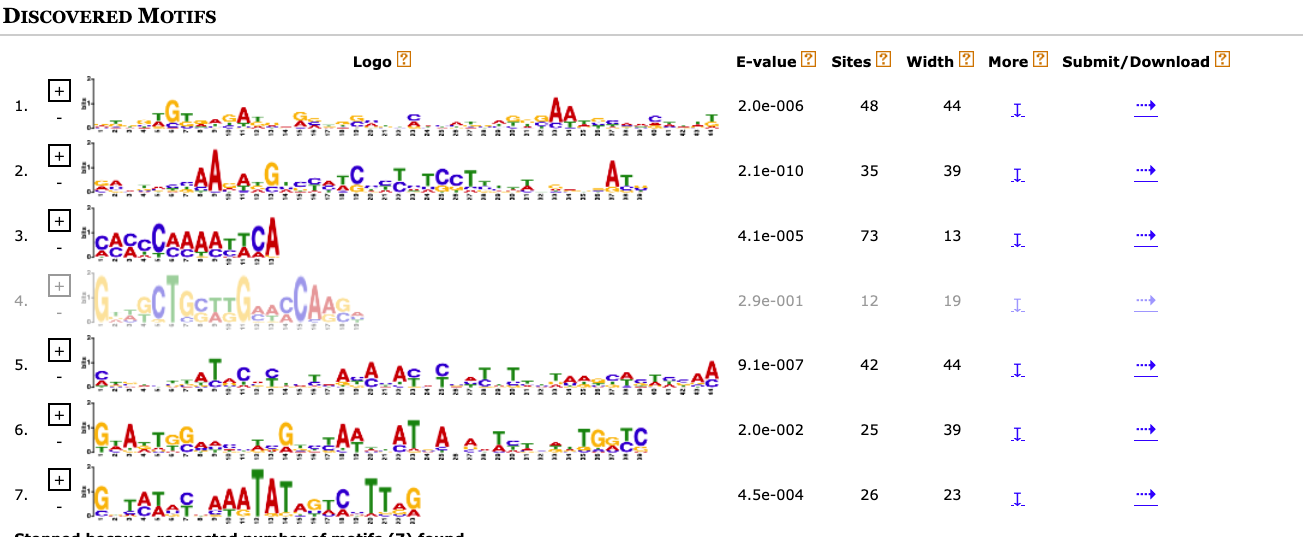

2nd try with 

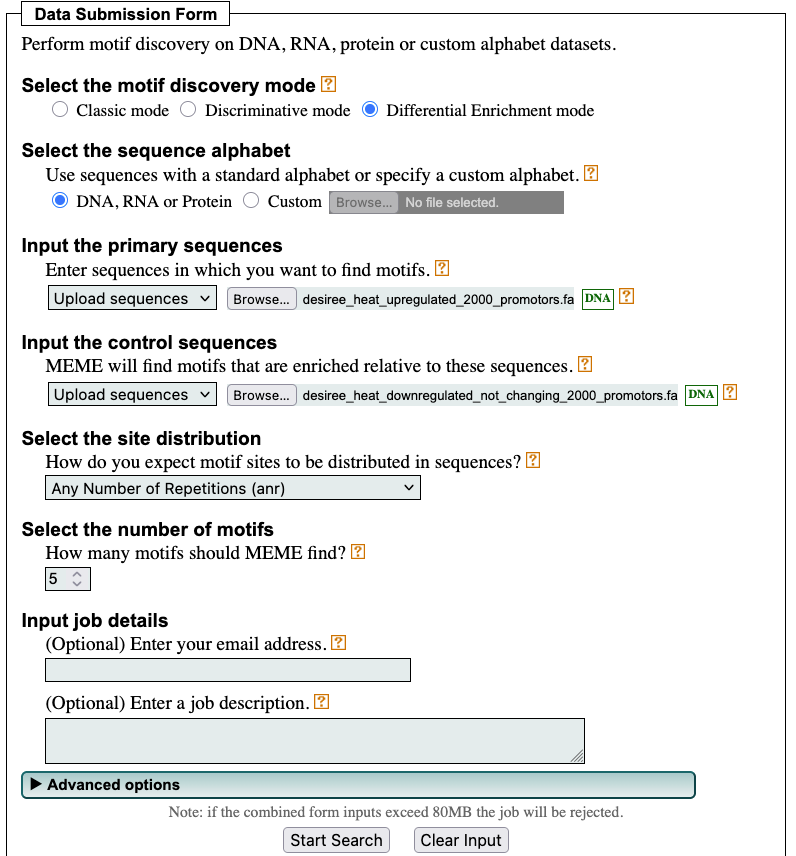


https://meme-suite.org/meme/info/status?service=MEME&id=appMEME_5.5.91769526549311849653149